## Stream real-time gainers and losers

#### Key Concepts
<ul>
<li>Use Flexreport Finance's Python client to subscribe topics</li>
<li>In this example, we subscribe to two topics--```biggest_mover```, ```biggest_loser```--and fetch the live charts for each name</li>
</ul>

In [ ]:
import pandas as pd
from flexreportfinance import FlexreportClient
import plotly.graph_objects as go
import ipywidgets as widgets

from collections import deque
from IPython.display import display, clear_output
from plotly.subplots import make_subplots

#### Setup a dashboard, create a FlexreportClient, subscribe to biggest_mover and biggest_loser, and stream events to dashboard

In [ ]:
# Import your client as appropriate
# from your_package import FlexreportClient

email = "" # fill this in with the email registered to Flexreport Finance
flexreport_pwd = "" # fill this in with your flexreport password


# --------------------------------------------------
# Dashboard setup
# --------------------------------------------------

MAX_CHARTS = 4
charts = deque(maxlen=MAX_CHARTS)

chart_output = widgets.Output(
    layout=widgets.Layout(width="100%")
)

display(chart_output)


# --------------------------------------------------
# Dashboard rendering
# --------------------------------------------------

def update_dashboard(symbol, symbol_data, event_type):

    series = symbol_data.get("series")

    if not series:
        print(f"No series data for {symbol}")
        print("Available keys:", list(symbol_data.keys()))
        return

    df = pd.DataFrame(series)

    required = {"date", "close", "zscore"}
    missing = required - set(df.columns)

    if missing:
        print(f"Missing fields: {missing}")
        print("Available columns:", list(df.columns))
        return

    df["date"] = pd.to_datetime(df["date"])
    df["close"] = pd.to_numeric(df["close"], errors="coerce")
    df["zscore"] = pd.to_numeric(df["zscore"], errors="coerce")

    df = (
        df.dropna(subset=["date", "close", "zscore"])
          .sort_values("date")
    )

    if df.empty:
        print(f"No valid observations for {symbol}")
        return

    charts.append({
        "symbol": symbol,
        "event_type": event_type,
        "df": df
    })

    # Dynamic subplot titles
    titles = [
        f"{chart['symbol']} - {chart['event_type']}"
        for chart in charts
    ]

    titles += [""] * (MAX_CHARTS - len(titles))

    # Create four subplots, each with two y-axes
    fig = make_subplots(
        rows=1,
        cols=MAX_CHARTS,
        specs=[[
            {"secondary_y": True},
            {"secondary_y": True},
            {"secondary_y": True},
            {"secondary_y": True}
        ]],
        subplot_titles=titles,
        horizontal_spacing=0.08
    )

    # --------------------------------------------------
    # Populate charts
    # --------------------------------------------------

    for i, chart in enumerate(charts):

        col = i + 1
        data = chart["df"]

        # Closing price
        fig.add_trace(
            go.Scatter(
                x=data["date"],
                y=data["close"],
                mode="lines",
                name=f"{chart['symbol']} Close",
                line=dict(width=2),
                hovertemplate=(
                    "Date: %{x|%Y-%m-%d}<br>"
                    "Close: $%{y:.2f}"
                    "<extra></extra>"
                )
            ),
            row=1,
            col=col,
            secondary_y=False
        )

        # Z-score
        fig.add_trace(
            go.Scatter(
                x=data["date"],
                y=data["zscore"],
                mode="lines",
                name=f"{chart['symbol']} Z-score",
                line=dict(width=1.5, dash="dash"),
                hovertemplate=(
                    "Date: %{x|%Y-%m-%d}<br>"
                    "Z-score: %{y:.2f}"
                    "<extra></extra>"
                )
            ),
            row=1,
            col=col,
            secondary_y=True
        )

        # Z-score thresholds
        for threshold in [2, -2]:

            fig.add_trace(
                go.Scatter(
                    x=data["date"],
                    y=[threshold] * len(data),
                    mode="lines",
                    line=dict(
                        dash="dot",
                        width=1
                    ),
                    showlegend=False,
                    hoverinfo="skip"
                ),
                row=1,
                col=col,
                secondary_y=True
            )

        # Axis labels
        fig.update_yaxes(
            title_text="Price ($)",
            row=1,
            col=col,
            secondary_y=False
        )

        fig.update_yaxes(
            title_text="Z-score",
            row=1,
            col=col,
            secondary_y=True
        )

    # --------------------------------------------------
    # Layout and styling
    # --------------------------------------------------

    fig.update_layout(
        template="plotly_dark",
        height=450,
        width=1800,
        title=dict(
            text="Flexreport Finance | Live Market Events",
            x=0.5
        ),
        hovermode="x unified",
        showlegend=False,
        margin=dict(l=50, r=50, t=90, b=60)
    )

    fig.update_xaxes(
        showgrid=True,
        tickangle=-35
    )

    # Hide unused panels
    for col in range(len(charts) + 1, MAX_CHARTS + 1):
        fig.update_xaxes(visible=False, row=1, col=col)
        fig.update_yaxes(visible=False, row=1, col=col)

    # Render updated dashboard
    with chart_output:
        clear_output(wait=True)
        display(fig)

    print(
        f"Dashboard updated: {symbol} "
        f"({len(charts)}/{MAX_CHARTS})"
    )


# --------------------------------------------------
# Event stream
# --------------------------------------------------

with FlexreportClient(
    email,
    password,
) as client:

    for event_id, event in client.events.stream(
        topics=["biggest_mover", "biggest_loser"]
    ):

        event_type = event.get("event_type")
        symbol = event.get("symbol")

        # Handle report_plan events
        if event_type == "report_plan":
            payload = event.get("payload") or {}
            event_type = payload.get("event_type")
            symbol = payload.get("symbol", symbol)

        if event_type not in {"biggest_mover", "biggest_loser"}:
            continue

        if not symbol:
            continue

        print(f"\nNEW EVENT: {symbol} - {event_type}")

        try:
            symbol_data = client.data.get_data(
                "/detect-intraday-outlier-jumps",
                parameters={"symbol": symbol}
            )

            update_dashboard(
                symbol,
                symbol_data,
                event_type
            )

        except Exception as exc:
            print(f"Error processing {symbol}: {exc}")

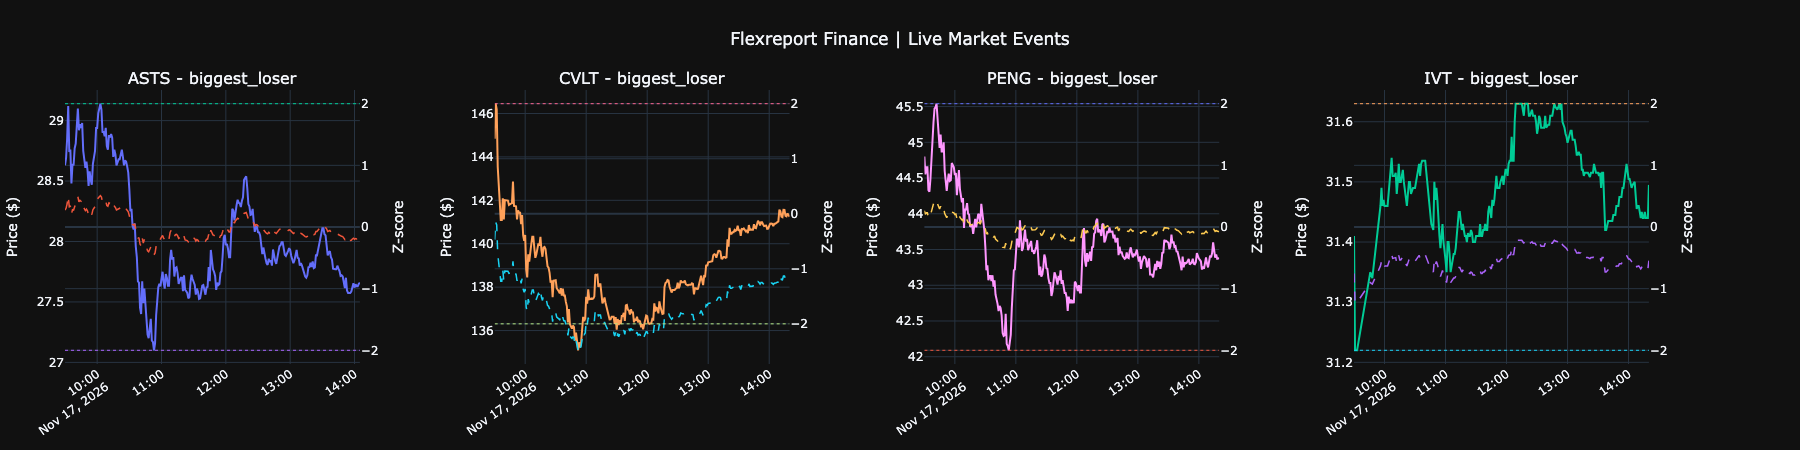